Resuming download from 1784676352 bytes (10142696834 bytes left)...
Resuming download to /root/.cache/kagglehub/datasets/armia123/plant-leaf-disease-classification/1.archive (1784676352/11927373186) bytes left.


100%|██████████| 11.1G/11.1G [09:05<00:00, 18.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/armia123/plant-leaf-disease-classification/versions/1
Top-level contents: ['val', 'train', 'test', 'train_balanced']
Found 94101 files belonging to 102 classes.
Found 11850 files belonging to 102 classes.
Number of classes: 102
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___alternaria_leaf_spot', 'Apple___brown_spot', 'Apple___gray_spot', 'Apple___healthy', 'Apple_leaf', 'Bell_pepper_leaf', 'Bitter_gourd___downy_mildew', 'Bitter_gourd___fusarium_wilt', 'Bitter_gourd___healthy', 'Bitter_gourd___mosaic_virus', 'Blueberry___healthy', 'Blueberry_leaf', 'Bottle_gourd___anthracnose', 'Bottle_gourd___downy_mildew', 'Bottle_gourd___healthy', 'Cassava___bacterial_blight', 'Cassava___brown_streak_disease', 'Cassava___green_mottle', 'Cassava___healthy', 'Cassava___mosaic_disease', 'Cauliflower___black_rot', 'Cauliflower___downy_mildew', 'Cauliflower___healthy', 'Cherry_(including_sour)___Powdery_mild

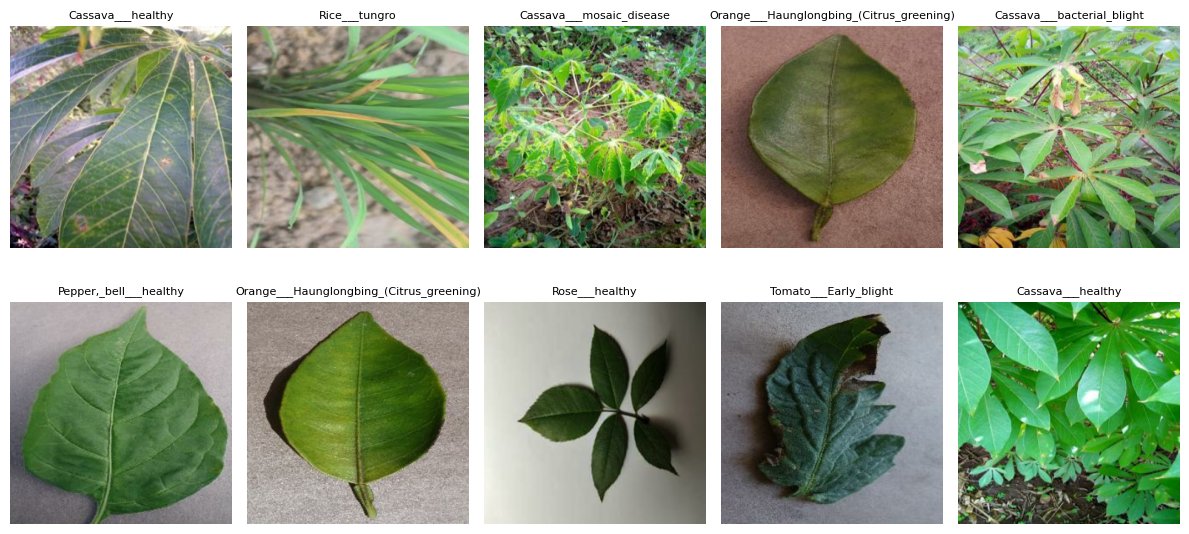

52606240/52606240 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b3 (Functional)  │ (None, 10, 10, 1536)   │    12,930,622 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        26,214 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,351,332 (50.93 MB)

 Trainable params: 420,198 (1.60 MB)

 Non-trainable params: 12,931,134 (49.33 MB)

Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 970s 4s/step - accuracy: 0.4697 - loss: 2.3406 - val_accuracy: 0.3219 - val_loss: 2.9738 - learning_rate: 0.0010
Epoch 2/15
 62/250 ━━━━━━━━━━━━━━━━━━━━ 10:52 3s/step - accuracy: 0.6197 - loss: 1.5388

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2B3
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import kagglehub
import os

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and set paths
# ----------------------------------------------------

path = kagglehub.dataset_download("armia123/plant-leaf-disease-classification")
print("Path to dataset files:", path)
print("Top-level contents:", os.listdir(path))

TRAIN_DIR = os.path.join(path, "train")
TEST_DIR = os.path.join(path, "test")

IMG_SIZE = (300, 300)   # EfficientNetV2B3's native/recommended input size
BATCH_SIZE = 16          # lowered since 300x300 + this model uses more memory than ResNet50V2

# ----------------------------------------------------
# STEP 2: Load Dataset from directories
# ----------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=True,
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Number of classes:", num_classes)
print("Classes:", class_names)

# ----------------------------------------------------
# STEP 3: Visualize Sample Images
# ----------------------------------------------------

plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(min(10, len(images))):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=8)
        plt.axis('off')
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 4: Preprocess - EfficientNetV2 preprocessing + Augment
# ----------------------------------------------------
# NOTE: EfficientNetV2's preprocess_input scales inputs to [-1, 1] internally,
# so no manual Rescaling(1./255) layer is needed here.

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_prepped = prepare(train_ds, training=True)
test_ds_prepped = prepare(test_ds, training=False)

# ----------------------------------------------------
# STEP 5: Build the Model (EfficientNetV2B3 Transfer Learning)
# ----------------------------------------------------

base_model = EfficientNetV2B3(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False   # freeze base for initial training

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.summary()

# ----------------------------------------------------
# STEP 6: Compile the Model (Phase 1 - frozen base)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# ----------------------------------------------------
# STEP 7: Train the Model (Phase 1 - frozen base)
# ----------------------------------------------------

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

history = model.fit(
    train_ds_prepped,
    epochs=15,
    steps_per_epoch=250,
    validation_data=test_ds_prepped,
    validation_steps=20,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 7b: Fine-tune - unfreeze top layers of EfficientNetV2B3
# ----------------------------------------------------

base_model.trainable = True

# Freeze all but the last ~50 layers (EfficientNetV2B3 is deeper than ResNet50V2)
for layer in base_model.layers[:-50]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # low LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_history = model.fit(
    train_ds_prepped,
    epochs=10,
    steps_per_epoch=250,
    validation_data=test_ds_prepped,
    validation_steps=20,
    callbacks=[early_stop, reduce_lr]
)

# Merge histories for plotting
for k in history.history:
    history.history[k] += fine_tune_history.history[k]

# ----------------------------------------------------
# STEP 8: Evaluate the Model
# ----------------------------------------------------

test_loss, test_acc = model.evaluate(test_ds_prepped)
print(f"\nTest Accuracy: {test_acc*100:.2f}%")

# ----------------------------------------------------
# STEP 9: Plot Training History
# ----------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 10: Confusion Matrix & Classification Report
# ----------------------------------------------------

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([y.numpy() for x, y in test_ds_prepped], axis=0)
y_pred_probs = model.predict(test_ds_prepped)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(8, num_classes * 0.6), max(6, num_classes * 0.5)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

# ----------------------------------------------------
# STEP 11: Predict on a Single New Leaf Image
# ----------------------------------------------------

def predict_leaf(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    img_array = preprocess_input(img_array)
    prediction = model.predict(img_array)
    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100
    print(f"Predicted: {predicted_class} ({confidence:.2f}% confidence)")
    return predicted_class, confidence

# Example usage:
# predict_leaf("dataset/test/Tomato___Early_blight/sample.jpg")

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('plant_disease_efficientnetv2b3_model.keras')
print("Model saved successfully!")